# Topic 4 - Statistics

---
**Note: Content extracted from CM3005 course materials (available via Coursera)**

---

---

**Topic Learning Objectives**:
1. Define population and sample and explain how these concepts are crucial in making valid visual representations of data
2. Distinguish descriptive and inferential statistic
3. Apply appropriate visualisation techniques to individual variables of each variable type
4. Cross-tabulate and group data to combine variables of different types
5. Visualise relationships between categorical variables
6. Visualise relationships between numerical and categorical variables
7. Visualise relationship between numerical variables
8. Analyse and quantify correlations between numerical variables

---

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 4.1 Introduction to Statistics </h2>
</div>

### Descriptive Statistics
- also called **summary statistics**
- provide quantitative descriptions or summaries of data
- helps us understand data
- helps us decide *what* data to present and *how*
- are the fundamental quantities visualised in many plot types

### Data is Critical
- vital that we know what/who any data represents
- how was it collected?
- why was it collected?
- who was involved?
- what **valid** conclusions can we draw?

### Sample and Population
- **Population**: the collection of all individuals or items under consideration
- **Sample**: the part of population from which information is obtained
  
  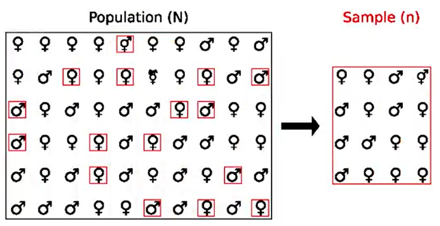
  
  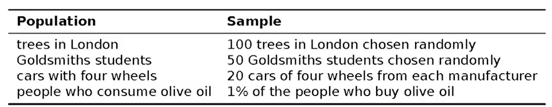

### Data Collection
- Limitations in data collection
- What is feasible?
    * Employee salary from one particular country?
- What is difficult or impossible?
    * Household income of the whole country?
    * Height of all 8 year old boys?

### Descriptive vs Inferential Statistics

- **Descriptive statistics**: Describe, show, or summarise data in a meaningful way such that patterns might emerge from the data
    * Examples:
        * a sports journalist produces a table of the fastest times in the 100m sprint in each Olympic Games over the past 60 years
        * a politician produces a bar chart showing the proportion of votes cast for each party in her constituency at a recent election
- **Inferential statistics**: Techniques that allow us to: (1) use samples to make generalisation about populations; (2) use data about the past to predict the future
    * Examples:
        * a tyre manufacture estimates the average life-span of their tyres
        * an economist estimates the average income of all Berlin residents


### Univariate and Multivariate Analysis

- **Univariate analysis**: Understand the shape, size and range of quantitative values (a single variable)
- **Multivariate analysis**: Explore the possible relationships between different combinations of variable types (many variables)

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 4.1 Descriptive Statistics </h2>
</div>

### Central Tendency

#### Measures of Central Tendency
- **mode**: most frequent score in data set
- **median**: middle score for a set of data arranged in order of magnitude
- **mean** ('average') 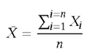

#### Appropriate Statistics for Different Variable Types
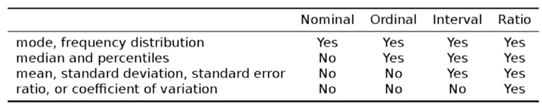

#### *1. Mode*

In [1]:
# ========================================================
# Example (Class Data) -- Mode of a categorical variable
# ========================================================

In [2]:
import pandas as pd

In [3]:
# Read the data file on students info (height and programme) (data created in Topic 2)
df = pd.read_csv('class_data.csv')
df['programme'] = df['programme'].astype('category')  # set category dtype
print(df.head())
print(df.info())

   gender  height         programme
0  female     NaN  Computer Science
1  female   162.0       Engineering
2     NaN     NaN       Engineering
3    male   153.0       Engineering
4  female   176.0       Engineering
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   gender     91 non-null     object  
 1   height     91 non-null     float64 
 2   programme  92 non-null     category
dtypes: category(1), float64(1), object(1)
memory usage: 1.9+ KB
None


In [4]:
# Count the number of students for each programme
counts = df['programme'].value_counts(dropna=False)
counts

programme
Engineering         41
Computer Science    28
Statistics          23
NaN                  8
Name: count, dtype: int64

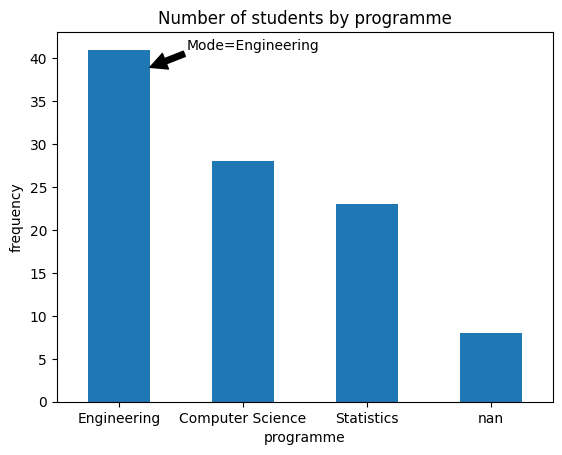

In [5]:
# Plot a bar chart showing number of students by programme
# Add a label to highlight the mode on the chart

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Plot the counts as a bar chart
ax = counts.plot.bar(rot=0)

ax.set_title('Number of students by programme')
ax.set_xlabel('programme')
ax.set_ylabel('frequency')

# Find the mode so we can label it on the plot
mode = df['programme'].mode()[0]

# Find the index of the mode in the plot
mode_pos = counts.index.get_loc(mode)

ax.annotate('Mode={}'.format(mode), 
            xy=(mode_pos + 0.25, counts[mode] * 0.95),  #arrow location
            xytext=(mode_pos + 0.55, counts[mode] * 1),  #text location
            arrowprops=dict(facecolor='black'))

plt.show()

In [6]:
mode = df['programme'].mode()[0]
print(mode)
print(counts[mode])
mode_pos = counts.index.get_loc(mode)
print(mode_pos)

Engineering
41
0


In [7]:
# What is the mode for 'programme' column?
print(df['programme'].mode()[0])
print(counts[df['programme'].mode()[0]])

Engineering
41


In [8]:
# ========================================================
# Example (Class Data) -- Mode of a numerical variable
# ========================================================

In [9]:
# Read the data file on students info (height and programme) (data created in Topic 2)
df = pd.read_csv('class_data.csv')
print(df.head())
print(df.info())

   gender  height         programme
0  female     NaN  Computer Science
1  female   162.0       Engineering
2     NaN     NaN       Engineering
3    male   153.0       Engineering
4  female   176.0       Engineering
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   gender     91 non-null     object 
 1   height     91 non-null     float64
 2   programme  92 non-null     object 
dtypes: float64(1), object(2)
memory usage: 2.5+ KB
None


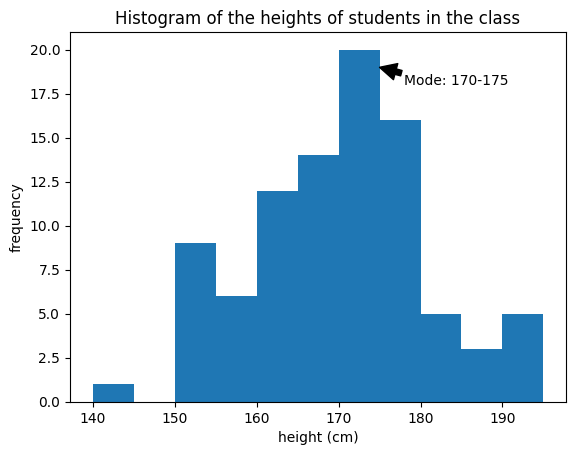

In [10]:
# Plot a histogram for the heights of students in a class (data created in Topic 2)
# Add a label to highlight the mode on the chart

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Read the data file
df = pd.read_csv('class_data.csv')

# Make one bin = 5cm
bin_size = 5
start = round(df['height'].min() / bin_size) * bin_size
end = df['height'].max() + bin_size

bins = np.arange(start, end, bin_size)

ax = df['height'].plot.hist(bins=bins)

ax.set_title('Histogram of the heights of students in the class')
ax.set_xlabel('height (cm)')
ax.set_ylabel('frequency')

hist, bin_edges = np.histogram(df['height'], bins=bins)
mode_bin = bin_edges[np.argmax(hist)]

ax.annotate(f'Mode: {mode_bin:.0f}-{mode_bin + bin_size:.0f}',
            xy=(mode_bin + bin_size, max(hist) * 0.95),  #arrow location
            xytext=(mode_bin + bin_size + 3, max(hist) * 0.9),  #text location
            arrowprops=dict(facecolor='black'))
plt.show()

In [11]:
print(start)
print(end)

140
199.0


In [12]:
print(bins)

[140. 145. 150. 155. 160. 165. 170. 175. 180. 185. 190. 195.]


In [13]:
np.histogram(df['height'], bins=bins)

(array([ 1,  0,  9,  6, 12, 14, 20, 16,  5,  3,  5], dtype=int64),
 array([140., 145., 150., 155., 160., 165., 170., 175., 180., 185., 190.,
        195.]))

In [14]:
hist, bin_edges = np.histogram(df['height'], bins=bins)
print(hist)
print(bin_edges)

[ 1  0  9  6 12 14 20 16  5  3  5]
[140. 145. 150. 155. 160. 165. 170. 175. 180. 185. 190. 195.]


In [15]:
np.argmax(hist)

6

In [16]:
bin_edges[np.argmax(hist)]

170.0

In [17]:
# What is the mode of the data in the histogram?
print(hist)       #frequency of each bin
print(bin_edges)  #start/end points of each bin
print(mode_bin)   #start point of bin with highest frequency (mode)

[ 1  0  9  6 12 14 20 16  5  3  5]
[140. 145. 150. 155. 160. 165. 170. 175. 180. 185. 190. 195.]
170.0


#### *2. Median*

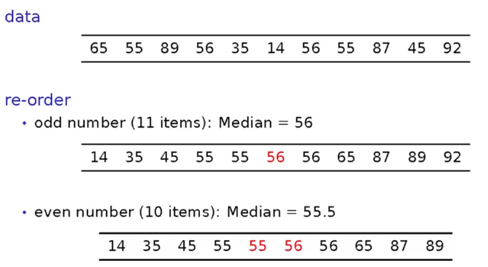

In [18]:
import pandas as pd
df = pd.DataFrame({'age':[65, 55, 89, 56, 35, 14, 56, 55, 87, 45, 92]})

In [19]:
### Insert code to calculate the median of the 'age' column in df


In [20]:
df['age'].median()

56.0

In [21]:
df1 = pd.DataFrame({'age':[65, 55, 89, 56, 35, 14, 56, 55, 87, 45, 92]})  # odd number of items (11)
print(df1.sort_values(by='age'))
print(df1['age'].median())

    age
5    14
4    35
9    45
1    55
7    55
3    56
6    56
0    65
8    87
2    89
10   92
56.0


In [22]:
df2 = pd.DataFrame({'age':[65, 55, 89, 56, 35, 14, 56, 55, 87, 45]})  # even number of items (10)
print(df2.sort_values(by='age'))
print(df2['age'].median())

   age
5   14
4   35
9   45
1   55
7   55
3   56
6   56
0   65
8   87
2   89
55.5


In [23]:
### Discuss the difference in how the median is derived for odd vs even number of values


#### *3. Mean*

In [24]:
import pandas as pd
df = pd.DataFrame({'age':[65, 55, 89, 56, 35, 14, 56, 55, 87, 45, 92]})

In [25]:
### Insert code to calculate the mean of the 'age' column in df


In [26]:
df['age'].mean()

59.0

In [27]:
sum(df['age']) / len(df['age'])

59.0

#### Example: Histogram with Mode, Median, Mean

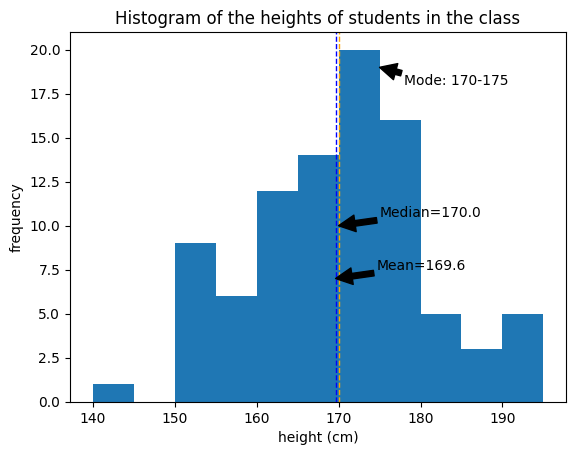

In [28]:
# ======================================================
# Example (Class Data) Revisited -- Mode, Median, Mean
# ======================================================

# Plot a histogram for the heights of students in a class (data created in Topic 2)
# Add labels to highlight the mode, median, and mean on the chart

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Read the data file
df = pd.read_csv('class_data.csv', index_col=0)

# Make one bin = 5cm
bin_size = 5
start = round(df['height'].min() / bin_size) * bin_size
end = df['height'].max() + bin_size

bins = np.arange(start, end, bin_size)

ax = df['height'].plot.hist(bins=bins)
ax.set_title('Histogram of the heights of students in the class')
ax.set_xlabel('height (cm)')
ax.set_ylabel('frequency')

hist, bin_edges = np.histogram(df['height'], bins=bins)
mode_bin = bin_edges[np.argmax(hist)]
ax.annotate(f'Mode: {mode_bin:.0f}-{mode_bin + bin_size:.0f}',
            xy=(mode_bin + bin_size, max(hist) * 0.95),  #arrow location
            xytext=(mode_bin + bin_size + 3, max(hist) * 0.9),  #text location
            arrowprops=dict(facecolor='black'))

median_val = df['height'].median()
ax.axvline(median_val, color='orange', linestyle='dashed', linewidth=1)
ax.annotate('Median={:0.1f}'.format(median_val), 
            xy=(median_val, 10),
            xytext=(median_val + 5, 10.5),
            arrowprops=dict(facecolor='black'))

mean_val = df['height'].mean()
ax.axvline(mean_val, color='blue', linestyle='dashed', linewidth=1)
ax.annotate('Mean={:0.1f}'.format(mean_val), 
            xy=(mean_val, 7),
            xytext=(mean_val + 5, 7.5),
            arrowprops=dict(facecolor='black'))

plt.show()

#### Why Sometimes Median is Better

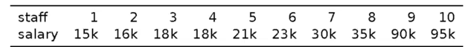

- mean salary of these 10 staff is 36.1k
- median is 22k
- median is not skewed so much by very large or small values

### Quartiles and Percentiles

In a rank-ordered data set:
- Q1: median of the first half
- Q2: median of the entire data set
- Q3: median of the second half

Different methods for computing Q1 and Q3:
- Include the Q2 data point in each 'half' or not?
    * yes for odd number of data items
    * default in pandas

Quartiles example (odd number of data items):


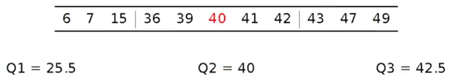


In [29]:
s = pd.Series([6, 7, 15, 36, 39, 40, 41, 42, 43, 47, 49], name='data')
s

0      6
1      7
2     15
3     36
4     39
5     40
6     41
7     42
8     43
9     47
10    49
Name: data, dtype: int64

In [30]:
### Insert code to compute the 1st, 2nd (median), and 3rd quartiles of the pandas Series s


In [31]:
s.median()

40.0

In [32]:
s.quantile([0.25, 0.5, 0.75])

0.25    25.5
0.50    40.0
0.75    42.5
Name: data, dtype: float64

In [33]:
### Insert code to calculate the 10th and 90th percentiles in the pandas Series s


In [34]:
s.quantile([0.10, 0.90])

0.1     7.0
0.9    47.0
Name: data, dtype: float64

In [35]:
import numpy as np
np.percentile(s, [10, 90])

array([ 7., 47.])

### Interquartile Range (IQR)

IQR: difference betwen the upper and lower quartiles
- IQR = Q3 - Q1
- the range of the middle 50% of your data


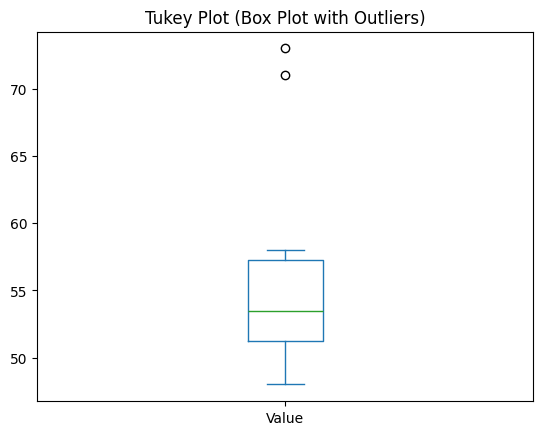

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

# Generate data that contains some outliers
data = [48, 50, 51, 52, 53, 54, 55, 58, 71, 73]
df = pd.DataFrame(data, columns=['Value'])

# Plot the data
ax = df.plot.box()
# ax = df.plot.box(vert=False)  # horizontal plot
ax.set_title('Tukey Plot (Box Plot with Outliers)')
plt.show()

In [38]:
### Insert code to compute the 1st and 3rd quartiles, as well as the IQR for the 'Value' column


In [39]:
df.head()

,Value
0,48
1,50
2,51
3,52
4,53


In [40]:
Q1 = df['Value'].quantile(0.25)
Q3 = df['Value'].quantile(0.75)
IQR = Q3 - Q1
print(Q1, Q3, IQR)

51.25 57.25 6.0


In [41]:
### Insert code to compute the lower and upper bounds (whiskers) of the Tukey box plot


In [42]:
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)
print(lower_bound, upper_bound)

42.25 66.25


### Standard Deviation

- Quantifies variation or dispersion from the mean
- High values = data is more spread out
- Low values = data is closer to the mean

- Definition:

    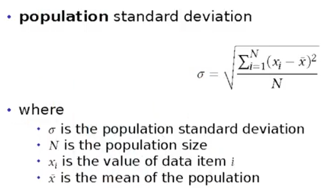

    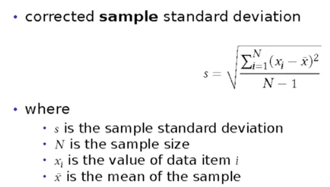

- Average distance that data points are spread from the mean


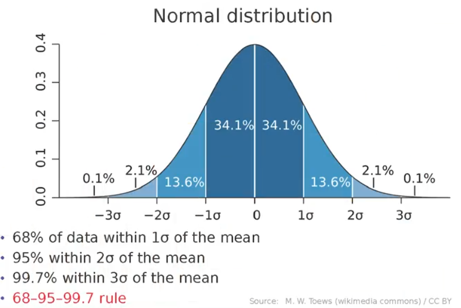

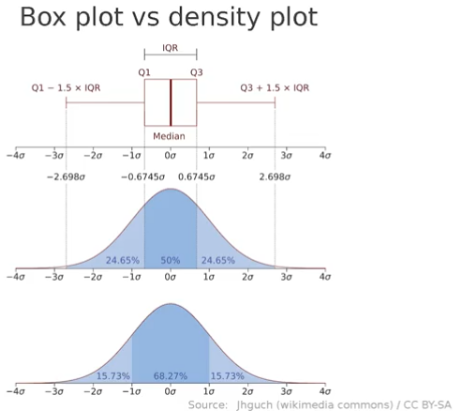

### Z-Score Normalisation

- Represents data values in terms of standard deviations from the mean
- Useful for comparing variables measured on different scales

  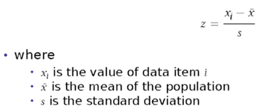

### Quantile Plot

- *f* quantile of a distribution is a number, *q*, where approximately a fraction *f* of the values of the distribution is less than or equal to *q*

    $$ f_i = \frac{i - 0.5}{N} $$

- where:
    - *i* indexes the data values sorted in ascending order, starting from 1
    - *N* is the number of data items


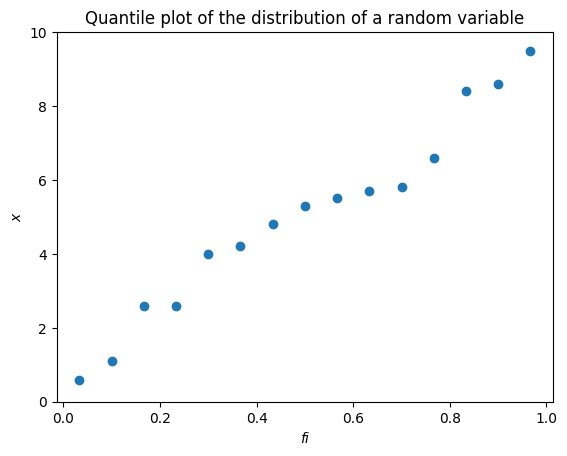

In [43]:
# Random data from Myatt and Johnson (2009), p.46
x = pd.Series([0.6, 1.1, 2.6, 2.6, 4.0, 4.2, 4.8, 5.3, 5.5, 5.7, 5.8, 6.6, 8.4, 8.6, 9.5])

# Define an f-value function to calculate normalised f-values
def fvalue(var):
    i = np.arange(1, len(var)+1)
    return (i - 0.5) / len(var)

fix, ax = plt.subplots()
ax.scatter(fvalue(x), x)
ax.set_ylim(0, 10)
ax.set_xlabel('$fi$')
ax.set_ylabel('$x$')
ax.set_title('Quantile plot of the distribution of a random variable')
plt.show()


### Quantile-Quantile (Q-Q) Plot

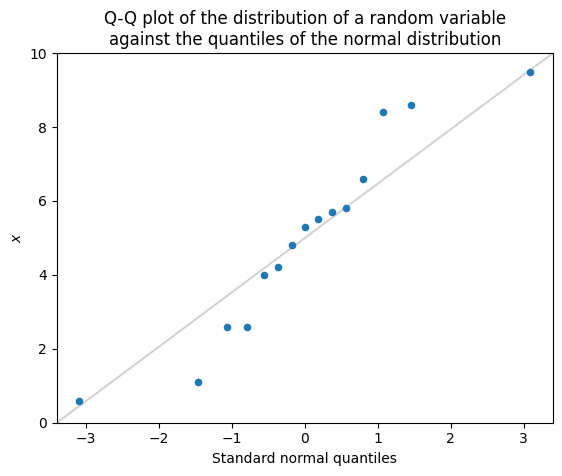

In [44]:
from scipy import stats

df = pd.DataFrame({'x': [0.6, 1.1, 2.6, 2.6, 4.0, 4.2, 4.8, 5.3, 
                         5.5, 5.7, 5.8, 6.6, 8.4, 8.6, 9.5]})

# Specify the quantities, avoiding 0 and 1 which correspond to infinity
# in the theoretical normal distribution
quantiles = np.linspace(0.001, 0.999, len(df))
df['norm_quantiles'] = stats.norm.ppf(quantiles, 0, 1)

ax = df.plot.scatter('norm_quantiles', 'x')

ax.set_ylim(0, 10)
ax.set_xlabel('Standard normal quantiles')
ax.set_ylabel('$x$')
ax.set_title('''Q-Q plot of the distribution of a random variable
against the quantiles of the normal distribution''')

# Plot a reference line
ax.plot([0,1], [0,1], transform=ax.transAxes, color='lightgrey', zorder=-1)

plt.show()


In [45]:
quantiles

array([0.001     , 0.07228571, 0.14357143, 0.21485714, 0.28614286,
       0.35742857, 0.42871429, 0.5       , 0.57128571, 0.64257143,
       0.71385714, 0.78514286, 0.85642857, 0.92771429, 0.999     ])

In [46]:
stats.norm.ppf(quantiles, 0, 1)

array([-3.09023231, -1.45897703, -1.06441033, -0.78968067, -0.56468842,
       -0.36534064, -0.17964844,  0.        ,  0.17964844,  0.36534064,
        0.56468842,  0.78968067,  1.06441033,  1.45897703,  3.09023231])

In [47]:
# Additional Reference -- https://statisticsbyjim.com/graphs/qq-plot/

### Shape - Skewness
- Quantifies the asymmetry of a distribution


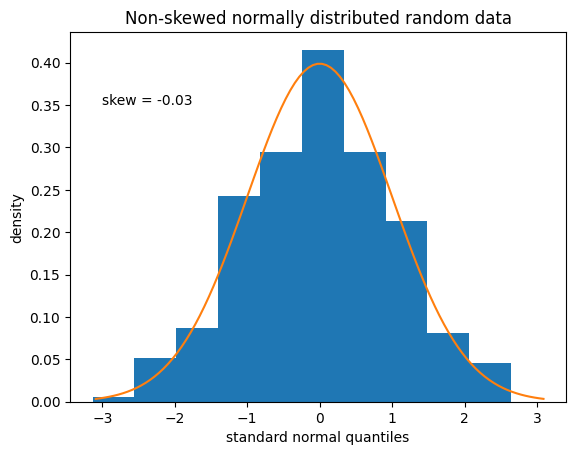

In [48]:
# Generate a non-skewed distribution

# Seed the random number generator
np.random.seed(8)

s = pd.Series(np.random.normal(0, 1, 300))  #normal dist with mean 0, sd 1
ax = s.plot.hist(density=True)

quantiles = np.linspace(stats.norm.ppf(0.001),
                        stats.norm.ppf(0.999), 100)
ax.plot(quantiles, stats.norm.pdf(quantiles))

ax.annotate(f'skew = {s.skew().round(2)}', xy=(-3, 0.35))
ax.set_xlabel('standard normal quantiles')
ax.set_ylabel('density')
ax.set_title('Non-skewed normally distributed random data')
plt.show()

In [49]:
quantiles

array([-3.09023231, -3.02780337, -2.96537444, -2.9029455 , -2.84051656,
       -2.77808763, -2.71565869, -2.65322976, -2.59080082, -2.52837189,
       -2.46594295, -2.40351402, -2.34108508, -2.27865614, -2.21622721,
       -2.15379827, -2.09136934, -2.0289404 , -1.96651147, -1.90408253,
       -1.8416536 , -1.77922466, -1.71679573, -1.65436679, -1.59193785,
       -1.52950892, -1.46707998, -1.40465105, -1.34222211, -1.27979318,
       -1.21736424, -1.15493531, -1.09250637, -1.03007744, -0.9676485 ,
       -0.90521956, -0.84279063, -0.78036169, -0.71793276, -0.65550382,
       -0.59307489, -0.53064595, -0.46821702, -0.40578808, -0.34335915,
       -0.28093021, -0.21850127, -0.15607234, -0.0936434 , -0.03121447,
        0.03121447,  0.0936434 ,  0.15607234,  0.21850127,  0.28093021,
        0.34335915,  0.40578808,  0.46821702,  0.53064595,  0.59307489,
        0.65550382,  0.71793276,  0.78036169,  0.84279063,  0.90521956,
        0.9676485 ,  1.03007744,  1.09250637,  1.15493531,  1.21

In [50]:
stats.norm.pdf(quantiles)

array([0.00336709, 0.00407561, 0.00491403, 0.00590188, 0.00706074,
       0.00841429, 0.00998831, 0.01181066, 0.01391117, 0.01632152,
       0.01907502, 0.02220632, 0.02575109, 0.02974556, 0.03422599,
       0.0392281 , 0.04478637, 0.05093331, 0.05769861, 0.06510827,
       0.0731837 , 0.08194076, 0.0913888 , 0.10152977, 0.11235727,
       0.1238558 , 0.136     , 0.14875408, 0.16207135, 0.17589399,
       0.19015298, 0.20476827, 0.21964919, 0.23469504, 0.24979609,
       0.26483461, 0.27968633, 0.29422199, 0.30830915, 0.32181412,
       0.33460403, 0.34654899, 0.35752424, 0.36741234, 0.37610524,
       0.38350623, 0.38953174, 0.39411292, 0.39719693, 0.39874797,
       0.39874797, 0.39719693, 0.39411292, 0.38953174, 0.38350623,
       0.37610524, 0.36741234, 0.35752424, 0.34654899, 0.33460403,
       0.32181412, 0.30830915, 0.29422199, 0.27968633, 0.26483461,
       0.24979609, 0.23469504, 0.21964919, 0.20476827, 0.19015298,
       0.17589399, 0.16207135, 0.14875408, 0.136     , 0.12385

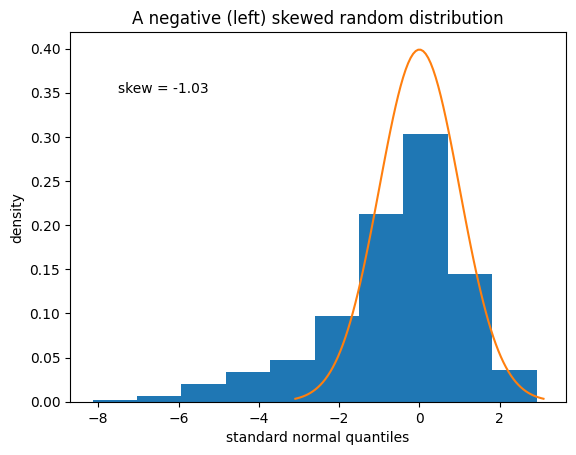

In [51]:
# Generate a negative (left) skewed distribution

# Seed the random number generator
np.random.seed(8)

s = pd.Series(np.random.normal(0, 1, 300))  #normal dist with mean 0, sd 1
add_data = pd.Series(np.random.normal(-2.5, 2.1, 100))  #normal dist with mean -2.5, sd 2.1
s = pd.concat([s, add_data], ignore_index=True)  #concatenate the two series

ax = s.plot.hist(density=True)

quantiles = np.linspace(stats.norm.ppf(0.001),
                        stats.norm.ppf(0.999), 100)
ax.plot(quantiles, stats.norm.pdf(quantiles))

ax.annotate(f'skew = {s.skew().round(2)}', xy=(-7.5, 0.35))
ax.set_xlabel('standard normal quantiles')
ax.set_ylabel('density')
ax.set_title('A negative (left) skewed random distribution')
plt.show()

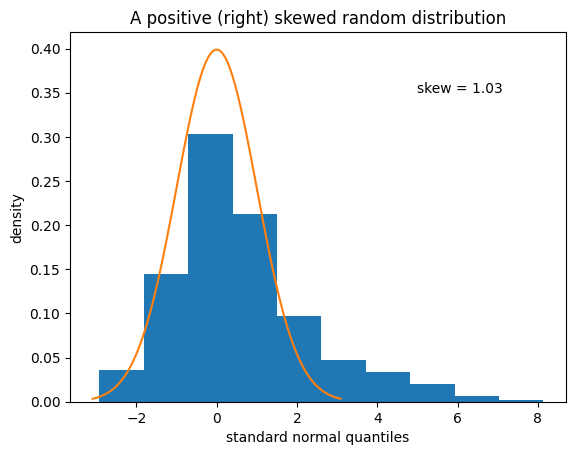

In [52]:
# Generate a positive (right) skewed distribution

# Seed the random number generator
np.random.seed(8)

s = pd.Series(np.random.normal(0, 1, 300))  #normal dist with mean 0, sd 1
add_data = pd.Series(np.random.normal(-2.5, 2.1, 100))  #normal dist with mean -2.5, sd 2.1
s = pd.concat([s, add_data], ignore_index=True)  #concatenate the two series
s = -s

ax = s.plot.hist(density=True)

quantiles = np.linspace(stats.norm.ppf(0.001),
                        stats.norm.ppf(0.999), 100)
ax.plot(quantiles, stats.norm.pdf(quantiles))

ax.annotate(f'skew = {s.skew().round(2)}', xy=(5, 0.35))
ax.set_xlabel('standard normal quantiles')
ax.set_ylabel('density')
ax.set_title('A positive (right) skewed random distribution')
plt.show()

### Shape - Kurtosis
- Quantifies the "tailedness"
- Shape of a distribution's tails in relation to its overall shape

In [53]:
# Additional References:
# https://statisticsbyjim.com/basics/kurtosis/
# https://pandas.pydata.org/docs/reference/api/pandas.Series.kurtosis.html
# https://en.wikipedia.org/wiki/Kurtosis

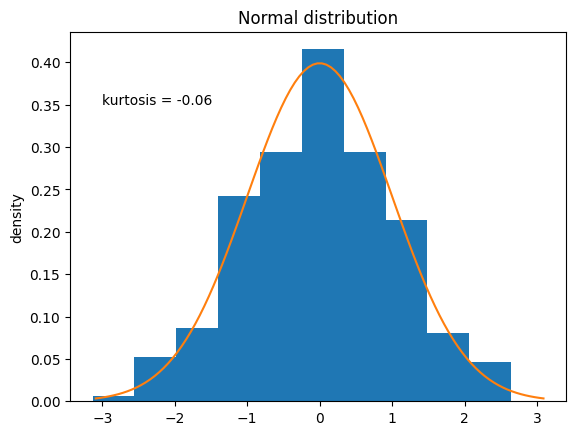

In [54]:
# Generate a normal kurtosis distribution

# Seed the random number generator
np.random.seed(8)

s = pd.Series(np.random.normal(0, 1, 300))  #normal dist with mean 0, sd 1
ax = s.plot.hist(density=True)

x = np.linspace(stats.norm.ppf(0.001),
                stats.norm.ppf(0.999), 100)
ax.plot(x, stats.norm.pdf(x))

ax.annotate(f'kurtosis = {s.kurtosis().round(2)}', xy=(-3, 0.35))
ax.set_ylabel('density')
ax.set_title('Normal distribution')
plt.show()


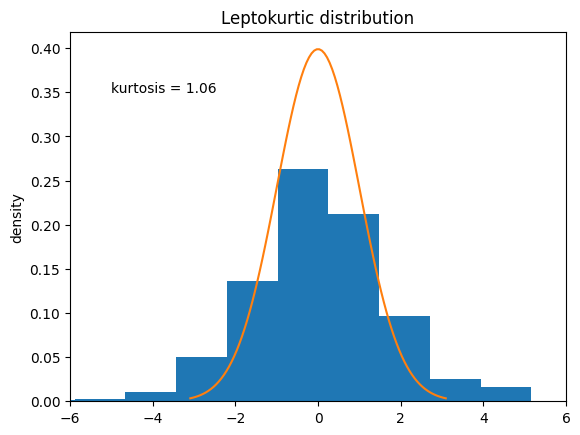

In [55]:
# Generate a leptokurtic distribution

# Seed the random number generator
np.random.seed(8)

s = pd.Series(np.random.normal(0, 1, 300))  #normal dist with mean 0, sd 1
add_data = pd.Series(np.random.normal(0, 2, 300))
s = pd.concat([s, add_data], ignore_index=True)  #concatenate the two series

ax = s.plot.hist(density=True)

x = np.linspace(stats.norm.ppf(0.001),
                stats.norm.ppf(0.999), 100)
ax.plot(x, stats.norm.pdf(x))

ax.annotate(f'kurtosis = {s.kurtosis().round(2)}', xy=(-5, 0.35))
ax.set_ylabel('density')
ax.set_xlim(-6, 6)
ax.set_title('Leptokurtic distribution')
plt.show()


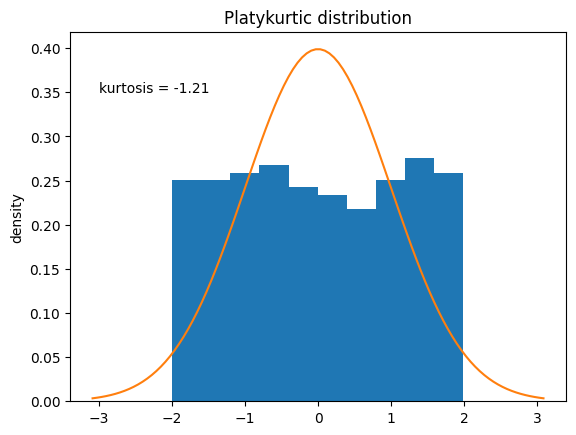

In [56]:
# Generate a platykurtic distribution

# Seed the random number generator
np.random.seed(5)

s = pd.Series(np.random.uniform(-2, 2, 300))  # no outliers
ax = s.plot.hist(density=True)

x = np.linspace(stats.norm.ppf(0.001),
                stats.norm.ppf(0.999), 100)
ax.plot(x, stats.norm.pdf(x))

ax.annotate(f'kurtosis = {s.kurtosis().round(2)}', xy=(-3, 0.35))
ax.set_ylabel('density')
ax.set_title('Platykurtic distribution')
plt.show()


In [ ]:
### Discuss the difference between mesokurtic, leptokurtic, platykurtic distributions
